# Covid-19 Data: Analytics, Visualizations, & Modeling

In 2020, the covid-19 pandemic rapidly spread through the world promptly sent the world into a state of panic and a series of lockdowns in hopes of preventing the virus from spreading further. Ultimately, between a combination of government policies, social changes,a vaccine and an overall increase in sanitation, by May 2023, the covid-19 pandemic was officially declared over.

## The Data

<i>"This data was scraped from woldometers.info on 2022-05-14 by Joseph Assaker. 225 countries are represented in this data."</i>

<i>"All of countries have records dating from 2020-2-15 until 2022-05-14 (820 days per country).
That's with the exception of China, which has records dating from 2020-1-22 until 2022-05-14 (844 days per country), and Palau which has records dating from 2021-8-25 until 2022-05-14 (263 days per country)."</i>

--------------------------------------------------------------------------------------------------------
**Summary Data Columns Description:**
    
- **country:** designates the Country in which the the row's data was observed.
    
- **continent:** designates the Continent of the observed country.
    
- **total_confirmed:** designates the total number of confirmed cases in the observed country.
    
- **total_deaths:** designates the total number of confirmed deaths in the observed country.
    
- **total_recovered:** designates the total number of confirmed recoveries in the observed country.
    
- **active_cases:** designates the number of active cases in the observed country.
    
- **serious_or_critical:** designates the estimated number of cases in serious or critical conditions in the observed country.
 
- **total_cases_per_1m_population:** designates the number of total cases per 1 million population in the observed country.
    
- **total_deaths_per_1m_population:** designates the number of total deaths per 1 million population in the observed country.
    
- **total_tests:** designates the number of total tests done in the observed country.
    
- **total_tests_per_1m_population:** designates the number of total test done per 1 million population in the observed country.
    
- **population:** designates the population count in the observed country.
    
**Daily Data Columns Description:**
    
- **date:** designates the date of observation of the row's data in YYYY-MM-DD format.
    
- **country:** designates the Country in which the the row's data was observed.
    
- **cumulative_total_cases:** designates the cumulative number of confirmed cases as of the row's date, for the row's country.
    
- **daily_new_cases:** designates the daily new number of confirmed cases on the row's date, for the row's country.
    
- **active_cases:** designates the number of active cases (i.e., confirmed cases that still didn't recover nor die) on the row's date, for the row's country.
    
- **cumulative_total_deaths:** designates the cumulative number of confirmed deaths as of the row's date, for the row's country.
    
- **daily_new_deaths:** designates the daily new number of confirmed deaths on the row's date, for the row's country.

## Libraries 


In [1]:
#Libraries for Statistical Analysis
import numpy as np #Numerical Manipulation
import pandas as pd #Dataframe Creation, Feature Engineering
import math #Additional Numerical Manipulation
from sklearn.linear_model import LinearRegression #Linear Regression


#Plotting and Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Reading in the "activity" csv file into a pandas dataframe
data = pd.read_csv('/kaggle/input/covid19-global-dataset/worldometer_coronavirus_daily_data.csv')
data_summary = pd.read_csv('/kaggle/input/covid19-global-dataset/worldometer_coronavirus_summary_data.csv')

## (1) Statistical Analysis

Exploring various stastical methods I can perform on the datasets

### (1.1) Summary Statistics

General summary statistics of both datasets, as provided by pandas functions

In [3]:
data.describe()

,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths
count,1.847870e+05,174329.000000,1.667470e+05,1.782270e+05,157850.000000
mean,7.251089e+05,2987.633285,6.239283e+04,1.388600e+04,39.831834
std,3.681471e+06,17803.232663,3.955641e+05,6.049521e+04,181.102770
min,0.000000e+00,-322.000000,-1.432100e+04,0.000000e+00,-39.000000
25%,1.099000e+03,0.000000,6.000000e+01,2.400000e+01,0.000000
50%,1.775600e+04,58.000000,1.386000e+03,3.040000e+02,1.000000
75%,2.238085e+05,728.000000,1.462050e+04,4.111000e+03,12.000000
max,8.420947e+07,909610.000000,1.793543e+07,1.026646e+06,5093.000000


In [4]:
data_summary.describe()

,total_confirmed,total_deaths,total_recovered,active_cases,serious_or_critical,total_cases_per_1m_population,total_deaths_per_1m_population,total_tests,total_tests_per_1m_population,population
count,2.260000e+02,2.180000e+02,2.040000e+02,2.040000e+02,145.000000,226.000000,218.000000,2.120000e+02,2.120000e+02,2.260000e+02
mean,2.305651e+06,2.884442e+04,2.256851e+06,6.861029e+04,269.482759,148156.809735,1157.550459,2.987445e+07,1.944650e+06,3.495521e+07
std,7.575510e+06,9.971254e+04,7.613357e+06,2.350430e+05,883.174727,155202.909225,1212.833590,1.079635e+08,3.318400e+06,1.390338e+08
min,2.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000,16.000000,2.000000,5.117000e+03,5.093000e+03,8.050000e+02
25%,2.412600e+04,2.370000e+02,1.619300e+04,2.397500e+02,5.000000,11748.250000,172.500000,3.472968e+05,1.667260e+05,5.605125e+05
50%,1.793750e+05,2.251500e+03,1.372740e+05,1.634000e+03,17.000000,98271.500000,768.000000,2.238918e+06,7.753355e+05,5.800570e+06
75%,1.090902e+06,1.400650e+04,1.006245e+06,1.929675e+04,139.000000,255632.750000,1850.000000,1.233862e+07,2.267408e+06,2.187284e+07
max,8.420947e+07,1.026646e+06,8.124426e+07,1.938567e+06,8318.000000,704302.000000,6297.000000,1.016883e+09,2.184247e+07,1.439324e+09


In [5]:
data.drop(['date','country'],axis=1).corr()

,cumulative_total_cases,daily_new_cases,active_cases,cumulative_total_deaths,daily_new_deaths
cumulative_total_cases,1.000000,0.568780,0.679464,0.913416,0.516627
daily_new_cases,0.568780,1.000000,0.810888,0.499613,0.595341
active_cases,0.679464,0.810888,1.000000,0.609694,0.627365
cumulative_total_deaths,0.913416,0.499613,0.609694,1.000000,0.586202
daily_new_deaths,0.516627,0.595341,0.627365,0.586202,1.000000


In [6]:
data_summary.drop(['country','continent'],axis=1).corr()

,total_confirmed,total_deaths,total_recovered,active_cases,serious_or_critical,total_cases_per_1m_population,total_deaths_per_1m_population,total_tests,total_tests_per_1m_population,population
total_confirmed,1.000000,0.905518,0.999800,0.730294,0.467644,0.132850,0.210908,0.878797,0.057582,0.420253
total_deaths,0.905518,1.000000,0.921612,0.585256,0.678045,0.022260,0.284079,0.775164,-0.010050,0.425389
total_recovered,0.999800,0.921612,1.000000,0.716899,0.468261,0.130081,0.234269,0.891476,0.066926,0.427036
active_cases,0.730294,0.585256,0.716899,1.000000,0.307591,0.141796,0.180904,0.560716,0.055022,0.130200
serious_or_critical,0.467644,0.678045,0.468261,0.307591,1.000000,-0.084683,0.154609,0.235215,-0.090568,0.222699
total_cases_per_1m_population,0.132850,0.022260,0.130081,0.141796,-0.084683,1.000000,0.475843,0.099096,0.609078,-0.133743
total_deaths_per_1m_population,0.210908,0.284079,0.234269,0.180904,0.154609,0.475843,1.000000,0.147738,0.193845,-0.076711
total_tests,0.878797,0.775164,0.891476,0.560716,0.235215,0.099096,0.147738,1.000000,0.205150,0.546679
total_tests_per_1m_population,0.057582,-0.010050,0.066926,0.055022,-0.090568,0.609078,0.193845,0.205150,1.000000,-0.088400
population,0.420253,0.425389,0.427036,0.130200,0.222699,-0.133743,-0.076711,0.546679,-0.088400,1.000000


### (1.2) Additional Summary Metrics

Additional metrics that are not shown by general summary stats from pandas

In [7]:
#Number of patients that had covid and survived
ad_metrics = pd.DataFrame()

ad_metrics["country"] = data_summary["country"]
ad_metrics["non_critical_cases"] = data_summary['total_confirmed'] - data_summary['serious_or_critical']
ad_metrics["test_confirmed_ratio"] = data_summary["total_tests"] / data_summary['total_confirmed']
ad_metrics['survival_ratio'] = data_summary['total_recovered'] / data_summary['total_deaths']

ad_metrics = ad_metrics.set_index('country')
ad_metrics = ad_metrics.replace({np.nan:0})

ad_metrics

,non_critical_cases,test_confirmed_ratio,survival_ratio
country,,,
Afghanistan,178143.0,5.306816,21.092588
Albania,275572.0,6.595434,77.731198
Algeria,265810.0,0.868499,25.944873
Andorra,42142.0,5.926511,268.111111
Angola,0.0,15.119816,51.131053
...,...,...,...
Wallis And Futuna Islands,0.0,45.171806,62.571429
Western Sahara,0.0,0.000000,9.000000
Yemen,11796.0,22.442931,4.192182


## (2) Feature Engineering

To compare the impact of the United States vs. the rest of the world, I am creating two pandas dataframes named us_data and global_data, so that I can easily model U.S stats to the global stats

In [8]:
#Creating the global dataframe
mask = data['country'] != 'USA'
global_data = data[mask]

#Creating the us dataframe
mask = data['country'] == 'USA' 
us_data = data[mask]

#Reindexing for the US dataset
index = np.arange(0,len(us_data),1)
us_data = us_data.set_index(index)

#Reindexing for the global dataset
index = np.arange(0,len(global_data),1)
global_data = global_data.set_index(index)

global_data['active_cases'] = global_data['active_cases'].fillna(0)

## (3) Visualizations

### (3.1) Visualizing US Covid-19 [2/15/2020 - 5/14/2022]

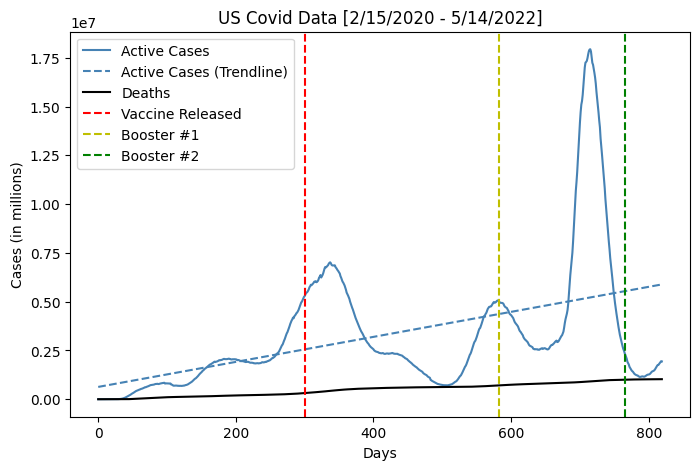

In [9]:
#Using linear regression to create a trend line of active cases
X = np.arange(0,len(us_data),1).reshape(-1,1)
y = us_data['active_cases']
model = LinearRegression().fit(X,y)
y_pred = model.predict(X)

#Creating the plot
plt.figure(figsize=(8,5))
#plt.plot(us_data['cumulative_total_cases'],label="Cumulative Total Cases") 
#plt.plot(us_data['daily_new_cases'],label="Daily New Cases")
plt.plot(us_data['active_cases'],label="Active Cases", color='steelblue')
plt.plot(y_pred,label="Active Cases (Trendline)",color='steelblue',linestyle='dashed')
plt.plot(us_data['cumulative_total_deaths'],label="Deaths", color='black')
plt.xlabel('Days')
plt.ylabel('Cases (in millions)')
plt.title("US Covid Data [2/15/2020 - 5/14/2022]")
plt.axvline(x=300,color='r',label='Vaccine Released',linestyle='dashed')
plt.axvline(x=583,color='y',label='Booster #1',linestyle='dashed')
plt.axvline(x=765,color='g',label='Booster #2',linestyle='dashed')
plt.legend()
plt.show()

### (3.2) Heatmap of top 10 countries w/ the highest populations [Scaled by 1e^6]

<Axes: title={'center': 'Global Heatmap [Scaled by 1e^6, descending by pop.]'}, ylabel='country'>

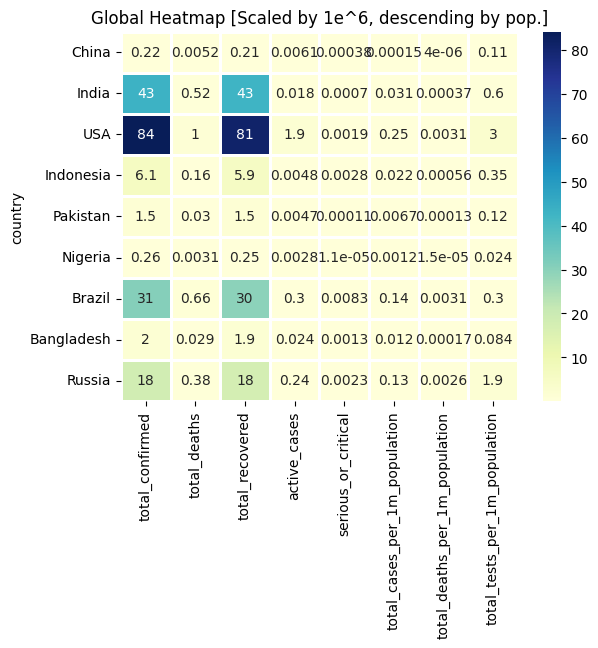

In [10]:
#mask = data_summary['country'] != "USA"
#heatmap = data_summary[mask]
heatmap = data_summary
heatmap = heatmap.set_index('country')
heatmap = heatmap.sort_values('population',ascending=False)[0:9]
heatmap = heatmap.drop(['continent','population','total_tests'],axis=1)
heatmap = heatmap * .000001
plt.xlabel('Category')
plt.ylabel('Country')
plt.title('Global Heatmap [Scaled by 1e^6, descending by pop.]')
sns.heatmap(heatmap, cmap='YlGnBu',annot=True,linewidths=2)